In [3]:
from sklearn.datasets import fetch_california_housing
housing = fetch_california_housing()
print(housing.data.shape, housing.target.shape)

(20640, 8) (20640,)


In [4]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    housing.data,
    housing.target,
    test_size=0.2,
    random_state=42,
)

In [5]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

linear_model = make_pipeline(
    StandardScaler(),
    LinearRegression(),
)

ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0),
)

linear_model.fit(x_train, y_train)
ridge_model.fit(x_train, y_train)

y_pred_linear = linear_model.predict(x_test)
y_pred_ridge = ridge_model.predict(x_test)

In [6]:
import numpy as np
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

y_true = np.asarray(y_test).ravel()

mse_linear = mean_squared_error(y_true, y_pred_linear)
rmse_linear = np.sqrt(mse_linear)
mae_linear = mean_absolute_error(y_true, y_pred_linear)
r2_linear = r2_score(y_true, y_pred_linear)

print("Linear:")
print(f"MSE:  {mse_linear:.4f}")
print(f"RMSE: {rmse_linear:.4f}")
print(f"MAE:  {mae_linear:.4f}")
print(f"R²:   {r2_linear:.4f}")

Linear:
MSE:  0.5559
RMSE: 0.7456
MAE:  0.5332
R²:   0.5758


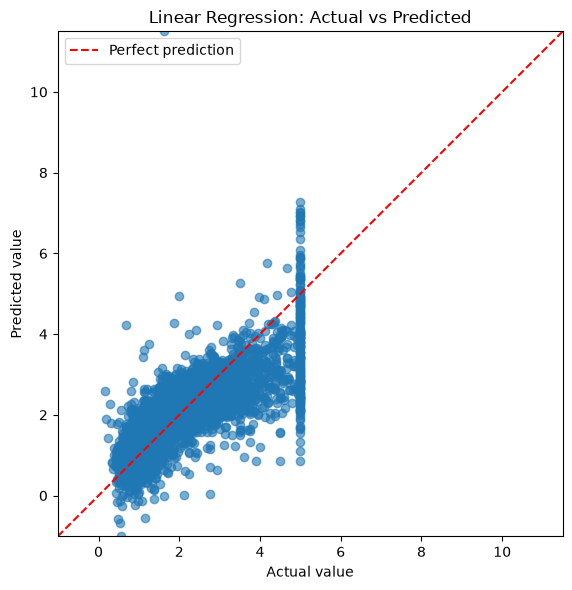

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))

plt.scatter(y_true, y_pred_linear, alpha=0.6)

# 理想预测：预测值 = 真实值
lower_linear = min(y_true.min(), y_pred_linear.min())
upper_linear = max(y_true.max(), y_pred_linear.max())

plt.plot(
    [lower_linear, upper_linear],
    [lower_linear, upper_linear],
    "r--",
    label="Perfect prediction",
)

plt.xlim(lower_linear, upper_linear)
plt.ylim(lower_linear, upper_linear)
plt.gca().set_aspect("equal", adjustable="box")
plt.xlabel("Actual value")
plt.ylabel("Predicted value")
plt.title("Linear Regression: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:

mse_ridge = mean_squared_error(y_true, y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)
mae_ridge = mean_absolute_error(y_true, y_pred_ridge)
r2_ridge = r2_score(y_true, y_pred_ridge)

print("Ridge:")
print(f"MSE:  {mse_ridge:.4f}")
print(f"RMSE: {rmse_ridge:.4f}")
print(f"MAE:  {mae_ridge:.4f}")
print(f"R²:   {r2_ridge:.4f}")

Ridge:
MSE:  0.5559
RMSE: 0.7456
MAE:  0.5332
R²:   0.5758


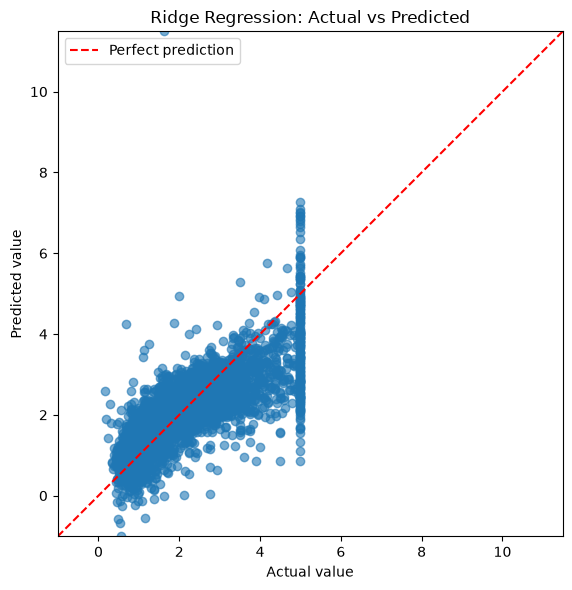

In [9]:
plt.figure(figsize=(6, 6))

plt.scatter(y_true, y_pred_ridge, alpha=0.6)

# 理想预测：预测值 = 真实值
lower_ridge = min(y_true.min(), y_pred_ridge.min())
upper_ridge = max(y_true.max(), y_pred_ridge.max())

plt.plot(
    [lower_ridge, upper_ridge],
    [lower_ridge, upper_ridge],
    "r--",
    label="Perfect prediction",
)

plt.xlim(lower_ridge, upper_ridge)
plt.ylim(lower_ridge, upper_ridge)
plt.gca().set_aspect("equal", adjustable="box")
plt.xlabel("Actual value")
plt.ylabel("Predicted value")
plt.title("Ridge Regression: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64


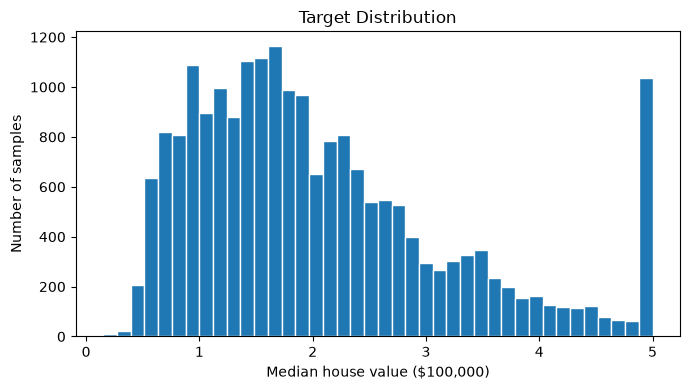

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(housing.data, columns=housing.feature_names)
df["MedHouseVal"] = housing.target

print(df["MedHouseVal"].describe())

plt.figure(figsize=(7, 4))
plt.hist(df["MedHouseVal"], bins=40, edgecolor="white")
plt.xlabel("Median house value ($100,000)")
plt.ylabel("Number of samples")
plt.title("Target Distribution")
plt.tight_layout()
plt.show()

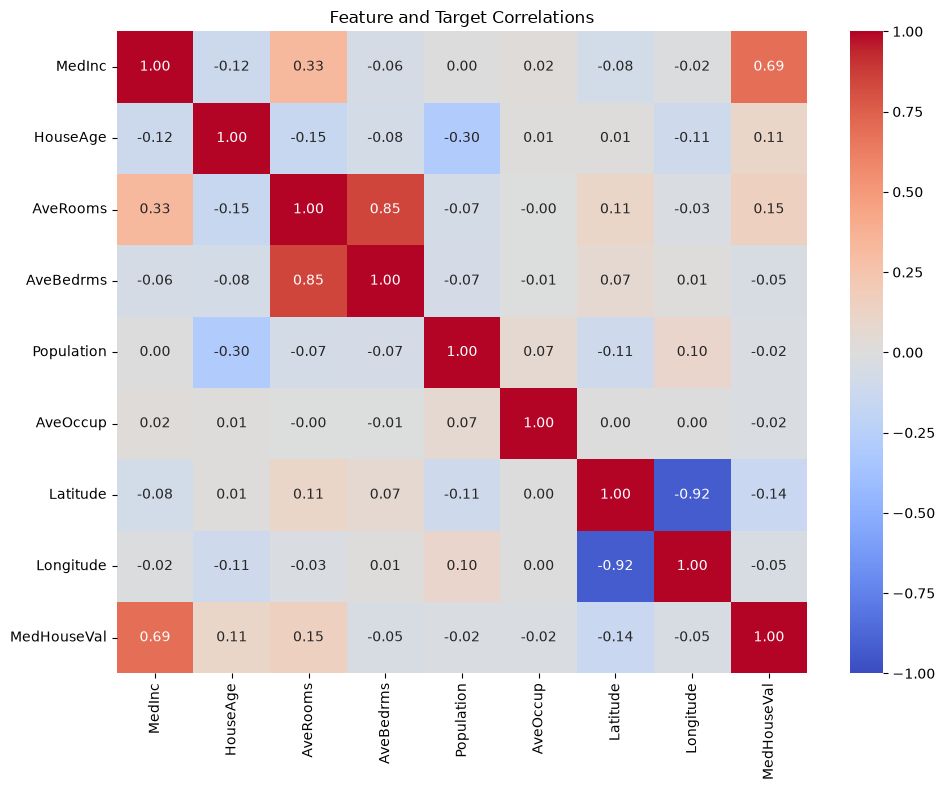

In [11]:
import seaborn as sns

corr = df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
)
plt.title("Feature and Target Correlations")
plt.tight_layout()
plt.show()